<a href="https://colab.research.google.com/github/DataAnalytics808/DASC-522-demo-repository/blob/main/demos/Homework_3_template_v5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> &nbsp; | &nbsp; [https://colab.research.google.com/github/DataAnalytics808/DASC-522-demo-repository/blob/main/demos/Homework_3_template_v5.ipynb](https://colab.research.google.com/github/DataAnalytics808/DASC-522-demo-repository/blob/main/demos/Homework_3_template_v5.ipynb)

This link is provided in case you are viewing this on GitHub, so that it is easy to open directly in Colab.

When opened in Colab, click "Copy to Drive" in the menu above to copy this file to your Colab account.


## Preamble

In [1]:
import sqlite3

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
import scipy.stats as stats
import seaborn as sns

import statsmodels.api as sm

# for regression
import statsmodels.formula.api as smf
from sklearn import datasets
from statistics import mean

## Import Database

In [3]:
import os
import sqlite3
import urllib.request

# Download database from GitHub if running in Colab / not present locally
db_filename = "weather_data.db"
if not os.path.exists(db_filename):
    url = f"https://raw.githubusercontent.com/DataAnalytics808/DASC-522-demo-repository/main/data/{db_filename}"
    urllib.request.urlretrieve(url, db_filename)

# Read database
my_connection = sqlite3.connect(db_filename)
my_cursor = my_connection.cursor()

query_result = my_cursor.execute("SELECT name FROM sqlite_master WHERE type='table'")
print(query_result.fetchall())


[('X_table',), ('y_table',)]


## Section 1: Data Loading


A. In a marked-up Python .ipynb file, create code to extract data from two tables (X_table & y_table) in the “weather_data.db” SQL database file. Load them into two dataframes df_X and dy_y.  Be sure to retain the “Record_ID” column in both dataframes – this is needed as the two tables aren’t in order. The tutorial covers this procedure.

X_table

In [6]:
data_X = my_cursor.execute("SELECT * FROM X_table").fetchall()

my_column_names = []

for column in query_result.description:
    my_column_names.append(column[0])

my_column_names

['MONTH',
 'DAY',
 'MONTHDAY',
 'HOUR',
 'IF4PMTO7AM',
 'DEWPOINTTEMPERATURE',
 'SEALEVELPRESSURE',
 'TEMP1',
 'TEMP2',
 'TEMP3',
 'TEMP4',
 'TEMP5',
 'TEMP6',
 'Record_ID']

In [8]:
df_X = pd.DataFrame(data_X, columns=my_column_names)
df_X

,MONTH,DAY,MONTHDAY,HOUR,IF4PMTO7AM,DEWPOINTTEMPERATURE,SEALEVELPRESSURE,TEMP1,TEMP2,TEMP3,TEMP4,TEMP5,TEMP6,Record_ID
0,1,1,1.0,1,1,3,1021.5,8,9,12,13,13,13,1
1,1,1,1.0,2,1,3,1021.7,8,8,9,12,13,13,2
2,1,1,1.0,3,1,3,1021.7,7,8,8,9,12,13,3
3,1,1,1.0,4,1,3,1021.3,7,7,8,8,9,12,4
4,1,1,1.0,5,1,3,1021.0,7,7,7,8,8,9,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42272,12,31,13.0,19,1,9,1017.6,18,16,14,12,11,10,42273
42273,12,31,13.0,20,1,9,1017.6,18,18,16,14,12,11,42274
42274,12,31,13.0,21,1,9,1017.9,18,18,18,16,14,12,42275
42275,12,31,13.0,22,1,9,1018.5,18,18,18,18,16,14,42276


y_table

In [9]:
data_Y = my_cursor.execute("SELECT * FROM Y_table").fetchall()

my_column_names = []

for column in query_result.description:
    my_column_names.append(column[0])

my_column_names

['Record_ID', 'AIRTEMPERATURE']

In [10]:
df_Y = pd.DataFrame(data_Y, columns=my_column_names)
df_Y

,Record_ID,AIRTEMPERATURE
0,17163,-14
1,17162,-14
2,17043,-13
3,17040,-13
4,8705,-13
...,...,...
42272,4835,33
42273,38683,33
42274,38684,33
42275,4071,33


A. Use the df.merge() class method to merge the two dataframes on the “Record_ID” column, into a dataframe called df_new. Other methods such as join() might result in the y values not matching with their corresponding X.

In [12]:
# df_new =
df_new = pd.merge(df_X, df_Y, on="Record_ID")
df_new

,MONTH,DAY,MONTHDAY,HOUR,IF4PMTO7AM,DEWPOINTTEMPERATURE,SEALEVELPRESSURE,TEMP1,TEMP2,TEMP3,TEMP4,TEMP5,TEMP6,Record_ID,AIRTEMPERATURE
0,1,1,1.0,1,1,3,1021.5,8,9,12,13,13,13,1,8
1,1,1,1.0,2,1,3,1021.7,8,8,9,12,13,13,2,7
2,1,1,1.0,3,1,3,1021.7,7,8,8,9,12,13,3,7
3,1,1,1.0,4,1,3,1021.3,7,7,8,8,9,12,4,7
4,1,1,1.0,5,1,3,1021.0,7,7,7,8,8,9,5,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42272,12,31,13.0,19,1,9,1017.6,18,16,14,12,11,10,42273,18
42273,12,31,13.0,20,1,9,1017.6,18,18,16,14,12,11,42274,18
42274,12,31,13.0,21,1,9,1017.9,18,18,18,16,14,12,42275,18
42275,12,31,13.0,22,1,9,1018.5,18,18,18,18,16,14,42276,17


B. Drop the “Record_ID”, “MONTH”, and “DAY” columns. Month and day aren’t needed because they are combined into a decimal MONTHDAY feature. For example, January 1st = 1.0, and January 16th = 1.5.

In [13]:
df_new = df_new.drop(columns=["Record_ID", "MONTH", "DAY"])
df_new

,MONTHDAY,HOUR,IF4PMTO7AM,DEWPOINTTEMPERATURE,SEALEVELPRESSURE,TEMP1,TEMP2,TEMP3,TEMP4,TEMP5,TEMP6,AIRTEMPERATURE
0,1.0,1,1,3,1021.5,8,9,12,13,13,13,8
1,1.0,2,1,3,1021.7,8,8,9,12,13,13,7
2,1.0,3,1,3,1021.7,7,8,8,9,12,13,7
3,1.0,4,1,3,1021.3,7,7,8,8,9,12,7
4,1.0,5,1,3,1021.0,7,7,7,8,8,9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
42272,13.0,19,1,9,1017.6,18,16,14,12,11,10,18
42273,13.0,20,1,9,1017.6,18,18,16,14,12,11,18
42274,13.0,21,1,9,1017.9,18,18,18,16,14,12,18
42275,13.0,22,1,9,1018.5,18,18,18,18,16,14,17


C.	Split df_new into X & y dataframes, where y only contains the “AIRTEMPERATURE” feature.

In [15]:
df_new_X = df_new.drop(columns=["AIRTEMPERATURE"])
df_new_X

,MONTHDAY,HOUR,IF4PMTO7AM,DEWPOINTTEMPERATURE,SEALEVELPRESSURE,TEMP1,TEMP2,TEMP3,TEMP4,TEMP5,TEMP6
0,1.0,1,1,3,1021.5,8,9,12,13,13,13
1,1.0,2,1,3,1021.7,8,8,9,12,13,13
2,1.0,3,1,3,1021.7,7,8,8,9,12,13
3,1.0,4,1,3,1021.3,7,7,8,8,9,12
4,1.0,5,1,3,1021.0,7,7,7,8,8,9
...,...,...,...,...,...,...,...,...,...,...,...
42272,13.0,19,1,9,1017.6,18,16,14,12,11,10
42273,13.0,20,1,9,1017.6,18,18,16,14,12,11
42274,13.0,21,1,9,1017.9,18,18,18,16,14,12
42275,13.0,22,1,9,1018.5,18,18,18,18,16,14


In [16]:
df_new_y = df_new[["AIRTEMPERATURE"]]
df_new_y

,AIRTEMPERATURE
0,8
1,7
2,7
3,7
4,6
...,...
42272,18
42273,18
42274,18
42275,17


## Section 2: Data Understanding & Modeling

A. Create a Data Understanding table & two python Data Understanding visualizations such as a scatterplot, histogram, pairplot, or correlation matrix.

In [17]:
df_new_X.describe()

,MONTHDAY,HOUR,IF4PMTO7AM,DEWPOINTTEMPERATURE,SEALEVELPRESSURE,TEMP1,TEMP2,TEMP3,TEMP4,TEMP5,TEMP6
count,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000,42277.000000
mean,7.027822,11.479244,0.626298,8.081037,1018.299371,14.322634,14.323060,14.323320,14.323675,14.323296,14.323036
std,3.466383,6.933393,0.483792,9.630972,6.034550,8.942710,8.944983,8.947777,8.950708,8.953527,8.955448
min,1.000000,0.000000,0.000000,-25.000000,986.600000,-14.000000,-14.000000,-14.000000,-14.000000,-14.000000,-14.000000
25%,4.033333,5.000000,0.000000,1.000000,1014.600000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
50%,7.033333,11.000000,1.000000,10.000000,1018.200000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000
75%,10.033333,17.000000,1.000000,17.000000,1022.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000
max,13.000000,23.000000,1.000000,24.000000,1039.800000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000


In [18]:
df_new_y.describe()

,AIRTEMPERATURE
count,42277.000000
mean,14.321853
std,8.940436
min,-14.000000
25%,8.000000
50%,16.000000
75%,21.000000
max,33.000000


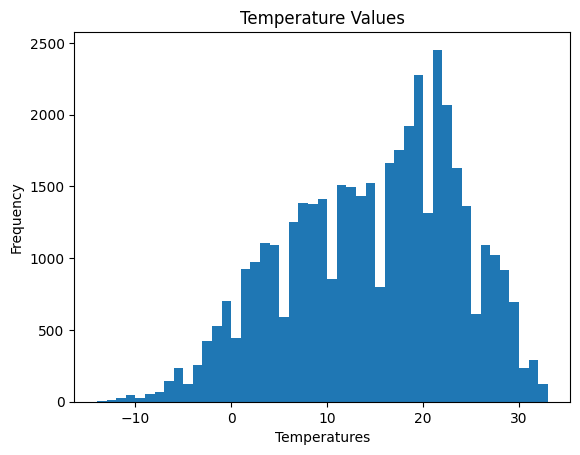

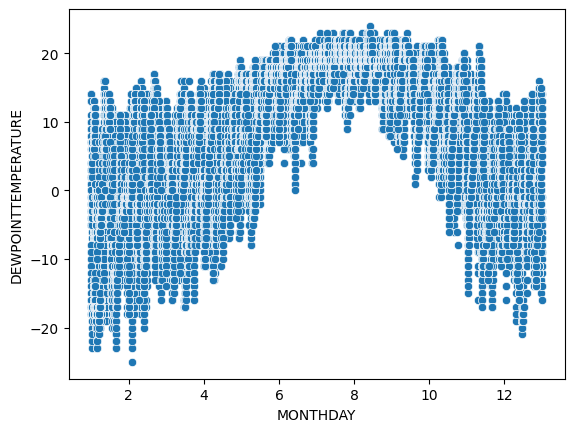

In [22]:
plt.hist(df_new_y, bins = 47)
plt.xlabel('Temperatures')
plt.ylabel('Frequency')
plt.title('Temperature Values')
plt.show()

sns.scatterplot(data=df_new_X,x='MONTHDAY',y='DEWPOINTTEMPERATURE')
plt.show()

#matrix = df.corr(numeric_only=True)
#sns.heatmap(matrix, annot=True)
#plt.show()

B. Full model: Model all variables using ols regression, and display a model summary

In [27]:
df_new_X = sm.add_constant(df_new_X)
sm.OLS(df_new_y, df_new_X).fit().summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                   Results: Ordinary least squares
======================================================================
Model:                OLS              Adj. R-squared:     0.985      
Dependent Variable:   AIRTEMPERATURE   AIC:                128190.5823
Date:                 2026-11-03 19:34 BIC:                128294.4063
No. Observations:     42277            Log-Likelihood:     -64083.    
Df Model:             11               F-statistic:        2.492e+05  
Df Residuals:         42265            Prob (F-statistic): 0.00       
R-squared:            0.985            Scale:              1.2141     
----------------------------------------------------------------------
                     Coef.   Std.Err.    t     P>|t|   [0.025   0.975]
----------------------------------------------------------------------
const               -10.5103   0.9631 -10.9128 0.0000 -12.3980 -8.6225
MONTHDAY             -0.0086   0.0016  -5.3519 0.0000  -0.0117 -0.0054
HOUR                  0.0240   0.0010  23.0960 0.0000   0.0219  0.0260
IF4PMTO7AM           -0.2323   0.0130 -17.8074 0.0000  -0.2578 -0.2067
DEWPOINTTEMPERATURE   0.0681   0.0013  50.6805 0.0000   0.0654  0.0707
SEALEVELPRESSURE      0.0109   0.0009  11.5107 0.0000   0.0090  0.0127
TEMP1                 1.2357   0.0049 252.5433 0.0000   1.2261  1.2453
TEMP2                -0.0943   0.0077 -12.1774 0.0000  -0.1094 -0.0791
TEMP3                -0.1410   0.0077 -18.2396 0.0000  -0.1561 -0.1258
TEMP4                -0.0674   0.0077  -8.7351 0.0000  -0.0825 -0.0523
TEMP5                -0.0323   0.0077  -4.2022 0.0000  -0.0474 -0.0173
TEMP6                 0.0170   0.0049   3.4461 0.0006   0.0073  0.0267
----------------------------------------------------------------------
Omnibus:              3888.950       Durbin-Watson:          2.012    
Prob(Omnibus):        0.000          Jarque-Bera (JB):       26973.198
Skew:                 -0.120         Prob(JB):               0.000    
Kurtosis:             6.906          Condition No.:          183145   
======================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
[2] The condition number is large, 1.83e+05. This might indicate
that there are strong multicollinearity or other numerical
problems.
"""

C.	BIC selection: Use the BIC analysis code from the “Analysis – AIC & BIC” section of the “4 Week 4A feature…” file to create a set of models.    

i.	Use the “BIC Analysis” code to find the best model using BIC. This takes about 3 minutes if you use Colab. Just FYI for this dataset the "best" AIC model contains all features, which is not interesting since the full model contains all features. The BIC model down-selects a bit.   

ii.	Display a model summary of the best BIC model.

In [30]:
from itertools import chain, combinations

def powerset(iterable):
    s=list(iterable)
    return chain.from_iterable(combinations(s,r) for r in range(1, len(s)+1))

mylist=list(powerset(list(df_new_X.columns)))
mylist=[list(row) for row in mylist]

print(mylist)

[['const'], ['MONTHDAY'], ['HOUR'], ['IF4PMTO7AM'], ['DEWPOINTTEMPERATURE'], ['SEALEVELPRESSURE'], ['TEMP1'], ['TEMP2'], ['TEMP3'], ['TEMP4'], ['TEMP5'], ['TEMP6'], ['const', 'MONTHDAY'], ['const', 'HOUR'], ['const', 'IF4PMTO7AM'], ['const', 'DEWPOINTTEMPERATURE'], ['const', 'SEALEVELPRESSURE'], ['const', 'TEMP1'], ['const', 'TEMP2'], ['const', 'TEMP3'], ['const', 'TEMP4'], ['const', 'TEMP5'], ['const', 'TEMP6'], ['MONTHDAY', 'HOUR'], ['MONTHDAY', 'IF4PMTO7AM'], ['MONTHDAY', 'DEWPOINTTEMPERATURE'], ['MONTHDAY', 'SEALEVELPRESSURE'], ['MONTHDAY', 'TEMP1'], ['MONTHDAY', 'TEMP2'], ['MONTHDAY', 'TEMP3'], ['MONTHDAY', 'TEMP4'], ['MONTHDAY', 'TEMP5'], ['MONTHDAY', 'TEMP6'], ['HOUR', 'IF4PMTO7AM'], ['HOUR', 'DEWPOINTTEMPERATURE'], ['HOUR', 'SEALEVELPRESSURE'], ['HOUR', 'TEMP1'], ['HOUR', 'TEMP2'], ['HOUR', 'TEMP3'], ['HOUR', 'TEMP4'], ['HOUR', 'TEMP5'], ['HOUR', 'TEMP6'], ['IF4PMTO7AM', 'DEWPOINTTEMPERATURE'], ['IF4PMTO7AM', 'SEALEVELPRESSURE'], ['IF4PMTO7AM', 'TEMP1'], ['IF4PMTO7AM', 'TEMP2']

In [33]:
BIC_scores=pd.DataFrame(columns=["BIC"])
for i in range(len(mylist)):
    BIC_scores.loc[i,'BIC']=sm.OLS(df_new_y,df_new_X[mylist[i]]).fit().bic

print(BIC_scores.sort_values(by='BIC').head(50))

                BIC
4016  128290.892898
4094  128294.406264
4082    128295.6318
4083  128301.414003
3916  128308.935748
4092  128312.395846
4061  128313.962265
4062  128319.395025
4084  128360.008728
4017  128365.248945
4063  128378.189746
3917  128383.831599
3961  128398.762731
4093  128402.709578
4071  128403.230529
3751  128404.931154
4081  128408.831566
4072  128409.350851
4006  128409.638737
3816  128412.269995
4007  128415.482572
4088  128416.080946
3531  128416.913502
4031  128417.098562
4067  128420.673863
3931  128421.949173
4032  128422.794952
3932   128427.39452
3800  128427.412347
4086  128431.825739
4022  128435.947377
4023   128436.22736
3515  128446.243415
4065  128450.445263
3923  128454.833542
3922  128454.957948
4018  128461.155091
4073  128468.737545
3962  128473.169864
4008  128474.988519
3918   128479.45912
3752  128479.758826
4033   128482.28172
3933  128486.989642
3817  128487.296897
3532  128492.308315
4024  128504.399445
3801  128513.272179
3924  128523.236486


In [34]:
mylist[4016]

['const',
 'MONTHDAY',
 'HOUR',
 'IF4PMTO7AM',
 'DEWPOINTTEMPERATURE',
 'SEALEVELPRESSURE',
 'TEMP1',
 'TEMP2',
 'TEMP3',
 'TEMP4']

In [36]:
df_best = sm.OLS(df_new_y, df_new_X[mylist[4016]]).fit()
df_best.summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                   Results: Ordinary least squares
======================================================================
Model:                OLS              Adj. R-squared:     0.985      
Dependent Variable:   AIRTEMPERATURE   AIC:                128204.3729
Date:                 2026-11-03 20:04 BIC:                128290.8929
No. Observations:     42277            Log-Likelihood:     -64092.    
Df Model:             9                F-statistic:        3.044e+05  
Df Residuals:         42267            Prob (F-statistic): 0.00       
R-squared:            0.985            Scale:              1.2145     
----------------------------------------------------------------------
                     Coef.   Std.Err.    t     P>|t|   [0.025   0.975]
----------------------------------------------------------------------
const               -10.4927   0.9632 -10.8931 0.0000 -12.3807 -8.6047
MONTHDAY             -0.0086   0.0016  -5.3570 0.0000  -0.0117 -0.0054
HOUR                  0.0237   0.0010  24.4266 0.0000   0.0218  0.0256
IF4PMTO7AM           -0.2334   0.0130 -17.9575 0.0000  -0.2589 -0.2079
DEWPOINTTEMPERATURE   0.0684   0.0013  53.5202 0.0000   0.0659  0.0709
SEALEVELPRESSURE      0.0109   0.0009  11.4980 0.0000   0.0090  0.0127
TEMP1                 1.2366   0.0049 253.0621 0.0000   1.2270  1.2462
TEMP2                -0.0936   0.0077 -12.1406 0.0000  -0.1088 -0.0785
TEMP3                -0.1423   0.0077 -18.5116 0.0000  -0.1574 -0.1272
TEMP4                -0.0834   0.0050 -16.8288 0.0000  -0.0931 -0.0737
----------------------------------------------------------------------
Omnibus:              3894.488       Durbin-Watson:          2.013    
Prob(Omnibus):        0.000          Jarque-Bera (JB):       27038.107
Skew:                 -0.121         Prob(JB):               0.000    
Kurtosis:             6.910          Condition No.:          183099   
======================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
[2] The condition number is large, 1.83e+05. This might indicate
that there are strong multicollinearity or other numerical
problems.
"""

D.	RFE selection: Use the “RFE iteration” code from the “Week 4A feature…” file to find the minimum set of features that achieves score = 0.980, which is equivalent to R2 = 0.980. You’ll need to modify the example code to display extra decimal places to determine this.   

i.	Display a model summary of the best RFE model.   

ii.	In a text block, mention which features do not contribute to improving model performance beyond R2 = 0.980.   



In [40]:
model = linear_model.LinearRegression()


print("\nSearch the best k features for k = 1 to 12\n")

for k in range(1, 12):
  # rfe = RFE(model, k)
  rfe = RFE(estimator = model, n_features_to_select = k)

  fit = rfe.fit(df_new_X, df_new_y)

  f = fit.get_support(1) #the most important features

  # final_features = data[data.columns[f]] # final features: this gives wrong results
  final_features = df_new_X[df_new_X.columns[f]] # final features

  print("Num Features: %d" % fit.n_features_)
  print("Selected Features: %s" % final_features.columns)
  print("Score: %2.3f" % fit.score(df_new_X,df_new_y))
  print("----------")



Search the best k features for k = 1 to 12

Num Features: 1
Selected Features: Index(['TEMP1'], dtype='object')
Score: 0.977
----------
Num Features: 2
Selected Features: Index(['IF4PMTO7AM', 'TEMP1'], dtype='object')
Score: 0.978
----------
Num Features: 3
Selected Features: Index(['IF4PMTO7AM', 'TEMP1', 'TEMP3'], dtype='object')
Score: 0.984
----------
Num Features: 4
Selected Features: Index(['IF4PMTO7AM', 'TEMP1', 'TEMP2', 'TEMP3'], dtype='object')
Score: 0.984
----------
Num Features: 5
Selected Features: Index(['IF4PMTO7AM', 'TEMP1', 'TEMP2', 'TEMP3', 'TEMP4'], dtype='object')
Score: 0.984
----------
Num Features: 6
Selected Features: Index(['IF4PMTO7AM', 'DEWPOINTTEMPERATURE', 'TEMP1', 'TEMP2', 'TEMP3', 'TEMP4'], dtype='object')
Score: 0.985
----------
Num Features: 7
Selected Features: Index(['HOUR', 'IF4PMTO7AM', 'DEWPOINTTEMPERATURE', 'TEMP1', 'TEMP2', 'TEMP3', 'TEMP4'], dtype='object')
Score: 0.985
----------
Num Features: 8
Selected Features: Index(['HOUR', 'IF4PMTO7AM', '

4 features need to be present to acheive an adjusted R2 value of .980. The features that do not not seem to improve model performance are as follows: TEMP2, TEMP4, DEWPOINTTEMPERATURE, HOUR, TEMP5, TEMP6, SEALEVELPRESSURE, and MONTHDAY

## Section 3: Model Evaluation


This modeling effort evaluated feature selection for predicting air temperature using OLS regression, comparing  Bayesian Information Criterion (BIC) selection with Recursive Feature Elimination (RFE). The baseline full model, which included all eleven features, achieved an adjusted $R^2$ of 0.985. Through structural down-selection, the optimal BIC model removed TEMP5 and TEMP6 while retaining nine variables, maintaining an identical adjusted $R^2$ of 0.985 with a significantly reduced Information Criterion score. The RFE process demonstrated that four-feature subset (IF4PMTO7AM, TEMP1, TEMP2, and TEMP3) was enough to achieve a target threshold score of 0.984. Any smaller subset of features did not acheive the required performance.

These results highlight a critical trade-off between model performance and complexity. While a larger feature set improves R-squared, it significantly more complex. In Conclusion, the four-variable RFE model represents the best trade-off of performance vs complexity.  


##Section 4: Capstone Project Plan

Add detail here regarding your proposed plan for your capstone project. The goal is for it to be beneficial to your current organization, a former organization, or to the DoD in general.   

As a reminder, CUI/PII/PHI topics or datasets are not allowed - your dataset must either be available online, or one that you collect or create.
*   Topic, including the label you will be predicting:
*   Type of problem (regression, binary classification, multiclass classification etc):
*   Will you use any advanced techniques like natural language processing, or using images as a model input? This is not required to be 100% successful:
*   Number of datapoints (300+ is best):
*   Number of features, a.k.a. variables or model inputs:

